# Notebook 02 — K-Means clustering (Solo project)
**Dependency:** First complete Notebook 01 to produce `data/clean_customers.csv`. Run all cells top to bottom using Shift+Enter.

## 1. Import ML libraries and read cleaned data
`StandardScaler` puts features on comparable scales. K-Means is an **unsupervised** algorithm: it does not need a correct label for each customer.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

current = Path.cwd()
ROOT = current if (current / "data").exists() else current.parent
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

clean_file = DATA_DIR / "clean_customers.csv"
if not clean_file.exists():
    raise FileNotFoundError(f"Run Notebook 01 to create clean_customers.csv: {clean_file}")
df = pd.read_csv(clean_file)
print("Loaded customer records:", len(df))
display(df.head())

Loaded customer records: 2240


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Response,Total_Spending,Purchase_Frequency,Preferred_Category,MntWines_Share,MntFruits_Share,MntMeatProducts_Share,MntFishProducts_Share,MntSweetProducts_Share,MntGoldProds_Share
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,1,1617,22,Wine,0.392703,0.054422,0.337662,0.106370,0.054422,0.054422
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,27,4,Wine,0.407407,0.037037,0.222222,0.074074,0.037037,0.222222
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,776,20,Wine,0.548969,0.063144,0.163660,0.143041,0.027062,0.054124
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,53,6,Meat,0.207547,0.075472,0.377358,0.188679,0.056604,0.094340
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,422,14,Wine,0.409953,0.101896,0.279621,0.109005,0.063981,0.035545


## 2. Choose the model features
We represent spending and purchase counts using `log1p`, which reduces skew from very large values. Recency is days since the latest purchase **at the historical time of data collection**. Six spending shares represent product preferences. Avoid `ID`, because it is only a customer identifier; avoid `Response`, because this project does not use outcome labels.

In [2]:
product_cols = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]
df["Log_Total_Spending"] = np.log1p(df["Total_Spending"])
df["Log_Purchase_Frequency"] = np.log1p(df["Purchase_Frequency"])

features = ["Log_Total_Spending", "Log_Purchase_Frequency", "Recency"] + [c + "_Share" for c in product_cols]
X = df[features].copy()
if X.isna().any().any():
    raise ValueError("Missing model features found. Recheck the cleaning steps in Notebook 01.")
print("Chosen ML features:", features)
display(X.head())

Chosen ML features: ['Log_Total_Spending', 'Log_Purchase_Frequency', 'Recency', 'MntWines_Share', 'MntFruits_Share', 'MntMeatProducts_Share', 'MntFishProducts_Share', 'MntSweetProducts_Share', 'MntGoldProds_Share']


,Log_Total_Spending,Log_Purchase_Frequency,Recency,MntWines_Share,MntFruits_Share,MntMeatProducts_Share,MntFishProducts_Share,MntSweetProducts_Share,MntGoldProds_Share
0,7.388946,3.135494,58,0.392703,0.054422,0.337662,0.106370,0.054422,0.054422
1,3.332205,1.609438,38,0.407407,0.037037,0.222222,0.074074,0.037037,0.222222
2,6.655440,3.044522,26,0.548969,0.063144,0.163660,0.143041,0.027062,0.054124
3,3.988984,1.945910,26,0.207547,0.075472,0.377358,0.188679,0.056604,0.094340
4,6.047372,2.708050,94,0.409953,0.101896,0.279621,0.109005,0.063981,0.035545


## 3. Standardize (scale) the features
Without scaling, a variable measured in hundreds can dominate one measured between 0 and 1. Standard scaling subtracts each feature's mean and divides by its standard deviation, so features become more comparable. Here all selected variables receive equal per-feature treatment.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Model matrix shape:", X_scaled.shape)
print("Mean of first scaled feature (approximately zero):", round(float(X_scaled[:, 0].mean()), 4))

Model matrix shape: (2240, 9)
Mean of first scaled feature (approximately zero): -0.0


## 4. Compare cluster numbers using two metrics
K-Means needs you to choose `k` (number of clusters). The **Elbow Method** plots inertia (within-cluster squared distances); **Silhouette Score** evaluates how well separated clusters are. Check 2 through 8 clusters. Higher silhouette generally indicates better separation, but interpretability also matters.

k=2: inertia=15299.17; silhouette=0.275
k=3: inertia=12944.75; silhouette=0.199
k=4: inertia=11331.89; silhouette=0.197
k=5: inertia=10647.27; silhouette=0.195
k=6: inertia=10016.96; silhouette=0.184
k=7: inertia=9439.19; silhouette=0.177
k=8: inertia=8925.95; silhouette=0.161


,k,inertia,silhouette_score
0,2,15299.170074,0.274931
1,3,12944.754882,0.198849
2,4,11331.894259,0.197362
3,5,10647.265642,0.194550
4,6,10016.963927,0.183872
5,7,9439.185293,0.177040
6,8,8925.946366,0.161485


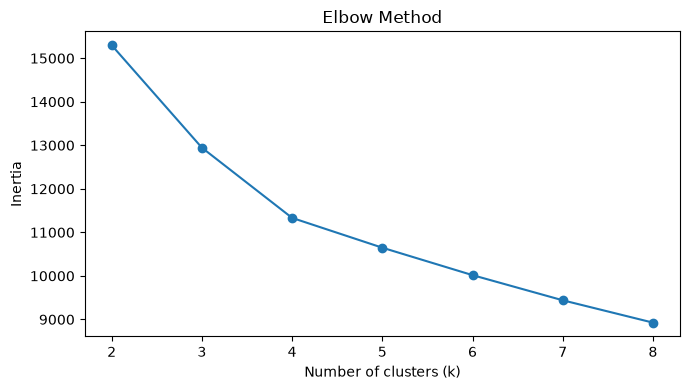

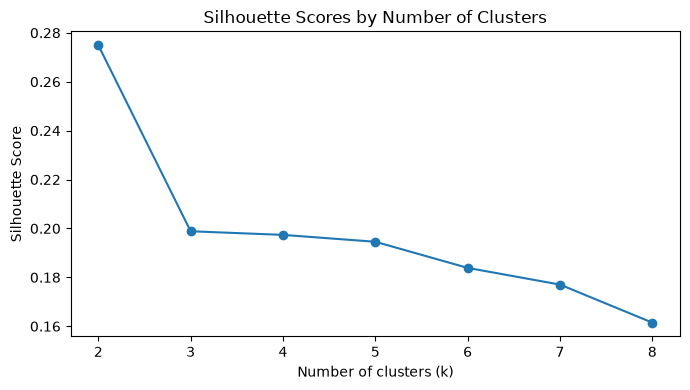

In [4]:
records = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels, sample_size=min(1500, len(df)), random_state=42)
    records.append({"k": k, "inertia": model.inertia_, "silhouette_score": score})
    print(f"k={k}: inertia={model.inertia_:.2f}; silhouette={score:.3f}")

scores = pd.DataFrame(records)
scores.to_csv(OUT_DIR / "model_selection.csv", index=False)
display(scores)

plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.tight_layout()
plt.savefig(FIG_DIR / "elbow_method.png", dpi=180)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["silhouette_score"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores by Number of Clusters")
plt.tight_layout()
plt.savefig(FIG_DIR / "silhouette_scores.png", dpi=180)
plt.show()

## 5. Train the final K-Means model
The code initially uses the **highest silhouette score** as its recommendation. After checking the elbow graph and business relevance, you can manually replace `best_k` with a justified value from 2 to 8. Do not invent a particular number of clusters before running the analysis.

In [5]:
best_k = int(scores.loc[scores["silhouette_score"].idxmax(), "k"])
print("Recommended number of clusters:", best_k)

final_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["Cluster"] = final_model.fit_predict(X_scaled)
print("Number of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())
final_score = silhouette_score(X_scaled, df["Cluster"], sample_size=min(1500, len(df)), random_state=42)
print("Final silhouette score:", round(final_score, 3))

Recommended number of clusters: 2
Number of customers in each cluster:
Cluster
0    1523
1     717
Name: count, dtype: int64
Final silhouette score: 0.275


## 6. PCA visualization
PCA reduces the 9-dimensional scaled features to two components for a **picture**. K-Means was trained on the full scaled feature set, NOT on the two PCA coordinates. Thus the 2D drawing can overlap even when high-dimensional groups differ.

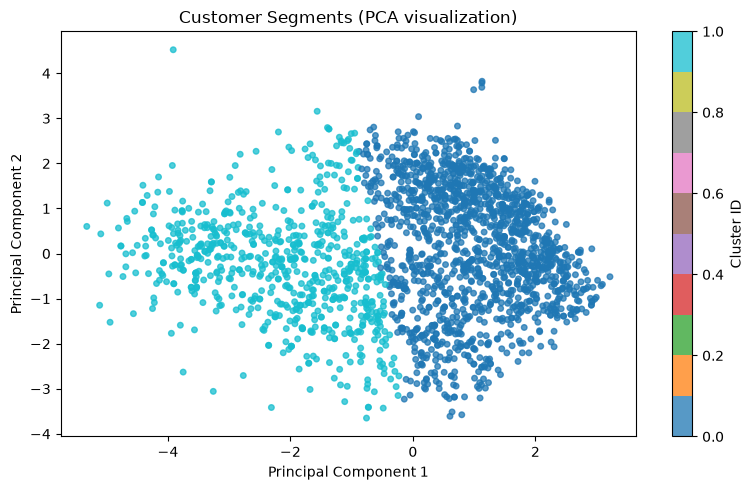

Variance shown by 2 PCA components: 53.8 %


In [6]:
pca = PCA(n_components=2)
points = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 5))
scatter = plt.scatter(points[:, 0], points[:, 1], c=df["Cluster"], cmap="tab10", s=16, alpha=0.75)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments (PCA visualization)")
plt.colorbar(scatter, label="Cluster ID")
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_clusters.png", dpi=180)
plt.show()
print("Variance shown by 2 PCA components:", round(float(sum(pca.explained_variance_ratio_)) * 100, 1), "%")

## 7. Profile each cluster
Compare original, understandable spending amounts, purchase counts, recency, and product amounts to describe segments. Cluster labels are arbitrary numbers, not 'good' or 'bad' customers.

,Customer_Count,Total_Spending,Purchase_Frequency,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
Cluster,,,,,,,,,,
0,1523,834.32,15.60,49.31,434.66,33.06,231.68,47.38,33.94,53.60
1,717,120.39,6.04,48.69,26.26,11.96,29.45,16.59,12.46,23.67


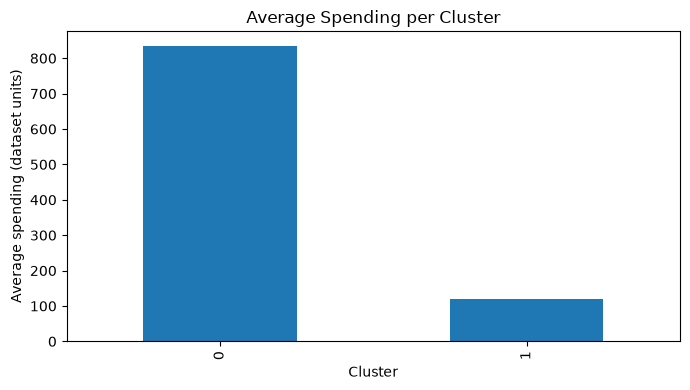

In [7]:
profile_cols = ["Total_Spending", "Purchase_Frequency", "Recency"] + product_cols
profiles = df.groupby("Cluster")[profile_cols].mean().round(2)
profiles.insert(0, "Customer_Count", df.groupby("Cluster").size())
display(profiles)

plt.figure(figsize=(7, 4))
df.groupby("Cluster")["Total_Spending"].mean().plot(kind="bar")
plt.ylabel("Average spending (dataset units)")
plt.title("Average Spending per Cluster")
plt.tight_layout()
plt.savefig(FIG_DIR / "average_spending_by_cluster.png", dpi=180)
plt.show()

## 8. Save the results
These output CSV files and graphs will be used by you in Notebook 03. The clean original customer dataset remains unchanged; the export adds a `Cluster` column.

In [8]:
clustered_file = OUT_DIR / "clustered_customers.csv"
profile_file = OUT_DIR / "cluster_profiles.csv"
df.to_csv(clustered_file, index=False)
profiles.to_csv(profile_file)
print("Saved:", clustered_file.resolve())
print("Saved:", profile_file.resolve())
print("Graphs saved in:", FIG_DIR.resolve())
assert clustered_file.exists() and profile_file.exists()

Saved: /home/darknight/Projects/learning/Customer-Segmentation-Project/outputs/clustered_customers.csv
Saved: /home/darknight/Projects/learning/Customer-Segmentation-Project/outputs/cluster_profiles.csv
Graphs saved in: /home/darknight/Projects/learning/Customer-Segmentation-Project/outputs/figures
